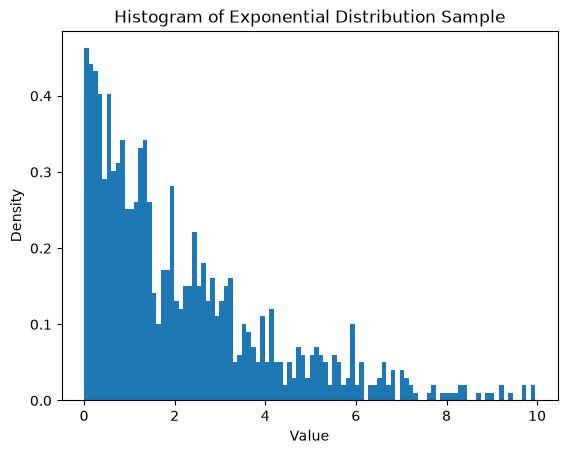

1000


In [105]:
import numpy as np 
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

n = 1000
# keep resampling until we get 1000 samples below 10
sample = np.array([])
while len(sample) < n:
    new_samples = np.random.exponential(scale=2.2, size=n)
    sample = np.concatenate([sample, new_samples[new_samples <= 10]])
sample = sample[:n]  


plt.hist(sample, bins=100, density=True)
plt.xlabel('Value') 
plt.ylabel('Density')
plt.title('Histogram of Exponential Distribution Sample')
plt.show()

print(len(sample))


In [106]:
mean = np.mean(sample)
variance = np.var(sample)
print(mean)
print(variance)

2.138527269651735
3.879984858439082


sample mean: 2.0952
sample sd: 0.0601
fitted mu = 2.0951 ± 0.0029
fitted sigma = 0.0596 ± 0.0024


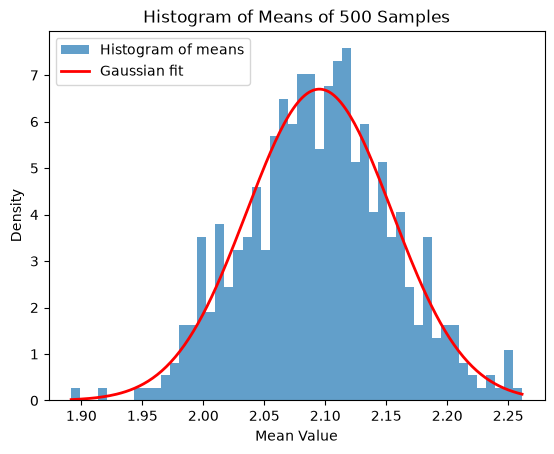

In [107]:
# create 1000 independent data sets of size 1000 each, and compute the mean of each data set
means = []
for _ in range(500):
    sample = np.array([])
    while len(sample) < n:
        new_samples = np.random.exponential(scale=2.2, size=n)
        sample = np.concatenate([sample, new_samples[new_samples <= 10]])
    sample = sample[:n]
    means.append(np.mean(sample))

# define Gaussian PDF for curve fitting
def gaussian(x, mu, sigma):
    return 1 / (sigma * np.sqrt(2 * np.pi)) * np.exp(-((x - mu) ** 2) / (2 * sigma ** 2))

# plot histogram
hist, bin_edges = np.histogram(means, bins=10000, density=True)
bin_centres = 0.5 * (bin_edges[:-1] + bin_edges[1:])

# fit Gaussian to histogram using curve_fit
p0 = [np.mean(means), np.std(means)]
popt, pcov = curve_fit(gaussian, bin_centres, hist, p0=p0)
perr = np.sqrt(np.diag(pcov))

mu_fit, sigma_fit = popt

mean = np.mean(means)
sd = np.std(means)
print(f"sample mean: {mean:.4f}")
print(f"sample sd: {sd:.4f}")
print(f"fitted mu = {mu_fit:.4f} ± {perr[0]:.4f}")
print(f"fitted sigma = {sigma_fit:.4f} ± {perr[1]:.4f}")

x = np.linspace(min(means), max(means), 200)
plt.hist(means, bins=50, density=True, alpha=0.7, label='Histogram of means')
plt.plot(x, gaussian(x, *popt), 'r-', linewidth=2, label='Gaussian fit')
plt.xlabel('Mean Value')
plt.ylabel('Density')
plt.title('Histogram of Means of 500 Samples')
plt.legend()
plt.show()





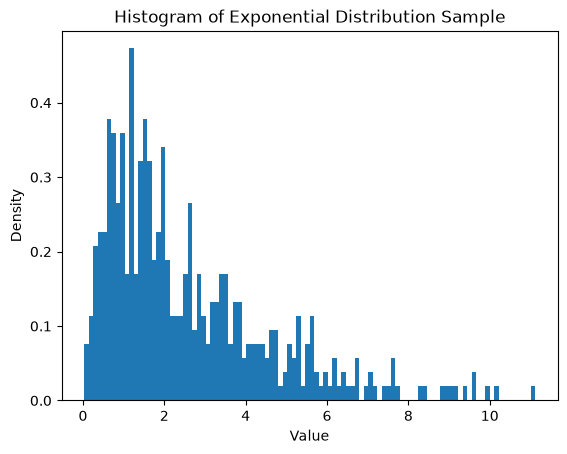

477


In [108]:
# add gaussian noise 

n = 1000
# keep resampling until we get 1000 samples below 10
sample = np.array([])
while len(sample) < n:
    new_samples = np.random.exponential(scale=2.2, size=n)
    sample = np.concatenate([sample, new_samples[new_samples <= 10]])
sample = sample[:n]  


noise = np.random.normal(loc=0, scale=0.5, size=n)
noise_positive = noise[noise > 0]
sample = sample[:len(noise_positive)] + noise_positive

plt.hist(sample, bins=100, density=True)
plt.xlabel('Value') 
plt.ylabel('Density')
plt.title('Histogram of Exponential Distribution Sample')
plt.show()

print(len(sample))


In [109]:
# calculate the bias and associated error 

bias = np.mean(sample) - 2.2
error = np.std(sample) / np.sqrt(len(sample))

print(f"Bias: {bias:.4f} ± {error:.4f}")

Bias: 0.3709 ± 0.0938
